# Prepare a qubit, then read a measurement

You have already used complex amplitude lists in **Build your intuition**. Here those lists become a one-qubit state that you can prepare, rotate in phase, and measure. We connect an exact probability calculation to the fluctuating results of a finite experiment.

A **qubit** is a quantum system with two chosen basis states. Write those states as `|0⟩ = [1, 0]` and `|1⟩ = [0, 1]`. The vertical bar and bracket are Dirac's **ket** notation for a state, not a special Python operation. A general pure state is `|ψ⟩ = α|0⟩ + β|1⟩`, stored as the ordered complex vector `[α, β]`. The Greek letters **alpha** (`α`) and **beta** (`β`) are amplitudes; **psi** (`ψ`) names the entire state.

**Model boundary:** one ideal qubit, exact gates, and projective measurements. There is no noise, time evolution between measurements, or experimental apparatus model. The Bloch coordinates describe a mathematical state, not a particle's location.

**Reproduce locally:** install the repository's `notebooks/requirements.txt` with Python 3.10 or newer, open this downloaded `.ipynb` in Jupyter, and choose **Restart Kernel and Run All**. On the website you are reading outputs saved from an actual run; editing and execution happen in your local notebook.

## 1. Prepare a trustworthy state model

NumPy's `1j` is the imaginary unit `i`, with `i² = −1`; `abs(z)**2` is a complex number's squared magnitude. `np.vdot(a, b)` conjugates `a` before taking its inner product with `b`. A valid state must satisfy `|α|² + |β|² = 1`.

The validator checks this requirement rather than quietly changing your input. It uses a numerical tolerance of `10⁻¹⁰` because floating-point arithmetic is approximate.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8.2, 3.8), "figure.dpi": 120,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#24354b", "text.color": "#24354b",
    "xtick.color": "#44556c", "ytick.color": "#44556c",
    "font.size": 11, "axes.titleweight": "bold",
    "axes.grid": True, "grid.alpha": 0.16,
    "grid.color": "#718198", "lines.linewidth": 2.4,
    "savefig.bbox": "tight",
})
BLUE, GREEN, AMBER = "#3c6db3", "#27836d", "#b87920"
TOLERANCE = 1e-10


def assert_state(state):
    state = np.asarray(state, dtype=complex)
    if state.shape not in ((2,), (4,)):
        raise ValueError("This model supports one or two qubits.")
    if not np.isfinite(state).all():
        raise ValueError("All amplitudes must be finite.")
    if not np.isclose(np.vdot(state, state).real, 1, atol=TOLERANCE, rtol=0):
        raise ValueError("The state must already be normalized.")
    return state


def probabilities(state):
    return np.abs(assert_state(state)) ** 2


print(f"Ready: NumPy {np.__version__}, Matplotlib {matplotlib.__version__}")
print("Ideal finite-dimensional model; every plot is computed by this notebook.")

Ready: NumPy 2.3.5, Matplotlib 3.10.8
Ideal finite-dimensional model; every plot is computed by this notebook.


## 2. Turn an unscaled vector into a prepared state

The list `[3, 4i]` is not yet a physical state: its squared magnitudes sum to `9 + 16 = 25`. Its **norm** (length) is the square root of this sum, so divide every entry by `5`. Normalization preserves the ratio of amplitudes and their relative phase.

In a **Z measurement**, the outcomes are `0` and `1` in the basis just defined. The Born rule gives `P(0) = |α|²` and `P(1) = |β|²`. Here `P` means probability, a dimensionless number between zero and one. Predict those two probabilities before reading the output.

In [2]:
def normalize(values):
    values = np.asarray(values, dtype=complex)
    norm = np.linalg.norm(values)
    if not np.isfinite(norm) or norm == 0:
        raise ValueError("Cannot normalize a zero or non-finite vector.")
    return assert_state(values / norm)


raw = np.array([3, 4j])
psi = normalize(raw)
print("Unscaled squared magnitudes:", np.abs(raw) ** 2)
print("Norm of unscaled vector:", np.linalg.norm(raw))
print("Prepared [alpha, beta]:", psi)
print("Z-basis [P(0), P(1)]:", probabilities(psi))
assert np.allclose(psi, [0.6, 0.8j])
assert np.allclose(probabilities(psi), [0.36, 0.64])
print("The imaginary amplitude contributes a positive probability of 0.64.")

Unscaled squared magnitudes: [ 9. 16.]
Norm of unscaled vector: 5.0
Prepared [alpha, beta]: [0.6+0.j  0. +0.8j]
Z-basis [P(0), P(1)]: [0.36 0.64]
The imaginary amplitude contributes a positive probability of 0.64.


## 3. Locate the state on the Bloch sphere

Choose a representative of the state with `α = cos(θ/2)` and `β = exp(iφ) sin(θ/2)`. The polar angle **theta** (`θ`) lies from `0` to `π`; the relative phase **phi** (`φ`) lies from `0` up to, but not including, `2π`. Angles in the code are **radians**; `π` radians equals `180°`. At the poles, the phase attached to a zero amplitude has no observable meaning.

A pure qubit has Bloch coordinates `x = 2 Re(conj(α)β)`, `y = 2 Im(conj(α)β)`, and `z = |α|² − |β|²`. `Re`, `Im`, and `conj` mean real part, imaginary part, and complex conjugate. These dimensionless coordinates obey `x² + y² + z² = 1`. Equivalently they are `(sin θ cos φ, sin θ sin φ, cos θ)`.

Set `θ = 60°`, `φ = 90°`. Predict the Z probability before running: `P(1) = sin²(θ/2) = sin²(30°)`. The two plots are **projections** of the same sphere point; being inside a projected circle does not mean the pure state lies inside the sphere.

State amplitudes: [0.866025+0.j  0.      +0.5j]
Bloch [x, y, z]: [0.       0.866025 0.5     ]
Z probabilities: [0.75 0.25]


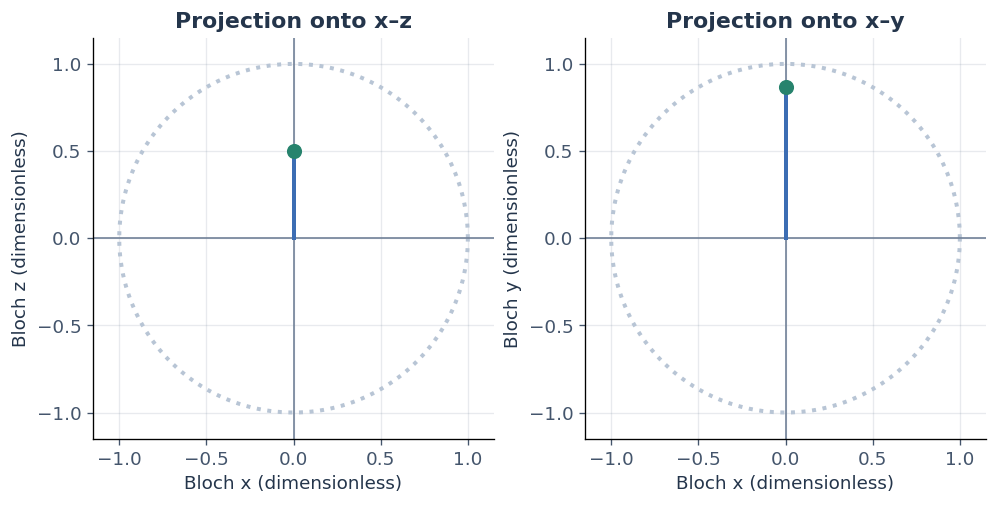

In [3]:
def qubit(theta, phi):
    return assert_state([np.cos(theta / 2), np.exp(1j * phi) * np.sin(theta / 2)])


def bloch(state):
    alpha, beta = assert_state(state)
    overlap = np.conj(alpha) * beta
    return np.array([2 * overlap.real, 2 * overlap.imag, abs(alpha)**2 - abs(beta)**2])


theta, phi = np.deg2rad([60, 90])
psi = qubit(theta, phi)
coordinates = bloch(psi)
print("State amplitudes:", np.round(psi, 6))
print("Bloch [x, y, z]:", np.round(coordinates, 6))
print("Z probabilities:", np.round(probabilities(psi), 6))
assert np.allclose(coordinates, [0, np.sqrt(3) / 2, 0.5])
assert np.isclose(coordinates @ coordinates, 1)
assert np.allclose(probabilities(psi), [0.75, 0.25])
circle = np.linspace(0, 2 * np.pi, 361)
fig, axes = plt.subplots(1, 2, figsize=(8.2, 4.0), layout="constrained")
for ax, (a, b), labels in zip(axes, [(0, 2), (0, 1)], [("x", "z"), ("x", "y")]):
    ax.plot(np.cos(circle), np.sin(circle), color="#b8c5d5", linestyle=":")
    ax.axhline(0, color="#718198", linewidth=1)
    ax.axvline(0, color="#718198", linewidth=1)
    ax.plot([0, coordinates[a]], [0, coordinates[b]], color=BLUE)
    ax.scatter(coordinates[a], coordinates[b], s=65, color=GREEN, zorder=3)
    ax.set(xlabel=f"Bloch {labels[0]} (dimensionless)", ylabel=f"Bloch {labels[1]} (dimensionless)",
           title=f"Projection onto {labels[0]}–{labels[1]}", xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), aspect="equal")
plt.show()

## 4. Separate global phase from relative phase

An **X measurement** has outcomes `+` and `−`, with basis states `|+⟩ = [1, 1]/sqrt(2)` and `|−⟩ = [1, −1]/sqrt(2)`. These are the plus/minus directions from the previous module. Their amplitudes are `(α + β)/sqrt(2)` and `(α − β)/sqrt(2)`.

The Hadamard matrix `H` computes these coordinates. Thus `abs(H @ ψ)**2` gives `[P(+), P(−)]`; `@` means matrix multiplication. In Bloch coordinates `P(+) = (1 + x)/2`, while `P(0) = (1 + z)/2`.

Rotating **only** `β` changes relative phase and can change X probabilities. Multiplying the **whole vector** by `exp(iγ)` adds a global phase (`γ`, gamma) and leaves every basis's probabilities unchanged: a shared unit-magnitude factor comes out of a linear inner product and vanishes when its squared magnitude is taken. Below, compare equal-magnitude states at three relative phases and check global phase separately.

Relative phase   0°: Z [0.5 0.5], X [1. 0.]
Relative phase  90°: Z [0.5 0.5], X [0.5 0.5]
Relative phase 180°: Z [0.5 0.5], X [0. 1.]


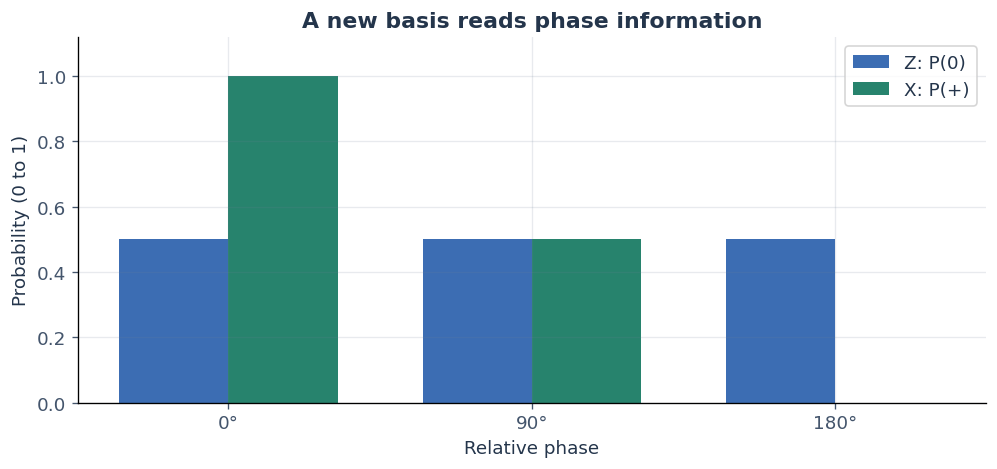

A shared 137° phase rotation changed neither basis's probabilities.


In [4]:
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)


def x_probabilities(state):
    return probabilities(H @ assert_state(state))


phases = np.deg2rad([0, 90, 180])
states = [qubit(np.pi / 2, phase) for phase in phases]
for degrees, state in zip([0, 90, 180], states):
    globally_rotated = np.exp(1j * np.deg2rad(137)) * state
    assert np.allclose(probabilities(globally_rotated), probabilities(state))
    assert np.allclose(x_probabilities(globally_rotated), x_probabilities(state))
    assert np.allclose(x_probabilities(state)[0], (1 + bloch(state)[0]) / 2)
    print(f"Relative phase {degrees:3d}°: Z {np.round(probabilities(state), 4)}, X {np.round(x_probabilities(state), 4)}")
fig, ax = plt.subplots(layout="constrained")
locations = np.arange(3)
ax.bar(locations - 0.18, [probabilities(s)[0] for s in states], width=0.36, color=BLUE, label="Z: P(0)")
ax.bar(locations + 0.18, [x_probabilities(s)[0] for s in states], width=0.36, color=GREEN, label="X: P(+)")
ax.set(xticks=locations, xticklabels=["0°", "90°", "180°"], xlabel="Relative phase", ylabel="Probability (0 to 1)",
       ylim=(0, 1.12), title="A new basis reads phase information")
ax.legend()
plt.show()
print("A shared 137° phase rotation changed neither basis's probabilities.")

## 5. Measure one qubit, then measure that same qubit again

In an ideal Z measurement, choose outcome `b` with probability `P(b)`. The **conditional post-measurement state** keeps only the chosen component and divides it by `sqrt(P(b))`. Conditional means that we know which result occurred. A phase attached to the only surviving component is global and has no effect on later probabilities.

If no operation or time evolution occurs between measurements, an immediate second Z measurement of **the same qubit** repeats the first result with certainty. This is different from preparing a fresh copy of the original state for each shot. A **shot** means one prepare–operate–measure trial.

We use a seeded random-number generator for reproducible saved examples. A seed fixes this simulation's sequence; it does not remove physical measurement randomness.

In [5]:
rng = np.random.default_rng(20261017)


def measure_z(state, generator):
    state = assert_state(state)
    if state.size != 2:
        raise ValueError("This measurement helper is for one qubit.")
    distribution = probabilities(state)
    outcome = int(generator.choice(2, p=distribution))
    post = np.zeros(2, dtype=complex)
    post[outcome] = state[outcome] / np.sqrt(distribution[outcome])
    return outcome, assert_state(post)


original = qubit(np.pi / 2, np.pi / 3)
first, post = measure_z(original, rng)
repeated = [measure_z(post, rng)[0] for _ in range(12)]
print("Original Z distribution:", np.round(probabilities(original), 6))
print("First result:", first)
print("Conditional post-measurement Z distribution:", np.round(probabilities(post), 6))
print("Twelve immediate Z repeats of that same post-measurement state:", repeated)
assert all(value == first for value in repeated)
assert np.isclose(probabilities(post)[first], 1)
print("The first result was random; the repeats are certain within this ideal model.")

Original Z distribution: [0.5 0.5]
First result: 1
Conditional post-measurement Z distribution: [0. 1.]
Twelve immediate Z repeats of that same post-measurement state: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
The first result was random; the repeats are certain within this ideal model.


## 6. Reprepare for every shot and estimate a probability

Now prepare the same original state **anew** for each of `N = 200` shots. Choose its angle to make the exact probability `p = P(1) = 0.35`. The phase is `60°`; it does not affect a Z measurement.

The estimate `p_hat` is the number of outcome-1 results divided by `N`. The hat means an estimate from data, not an exact Born probability. Sampling directly from the exact distribution is equivalent to independent fresh preparations in this ideal model. We do not feed a measured state into the next shot.

Fresh preparations: 200
Exact [P(0), P(1)]: [0.65 0.35]
Observed [count(0), count(1)]: [127  73]
Estimated probabilities: [0.635 0.365]
Estimate minus exact P(1): +0.0150


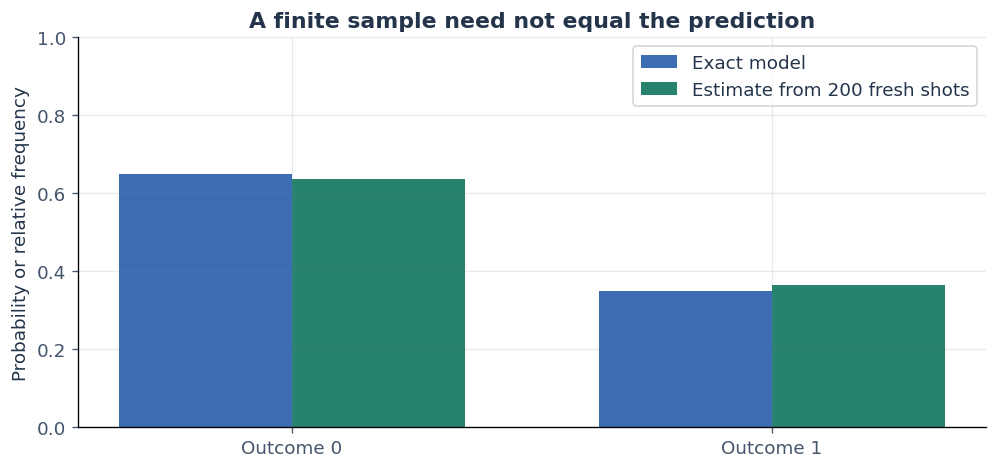

In [6]:
p, shots = 0.35, 200
prepared = qubit(2 * np.arcsin(np.sqrt(p)), np.pi / 3)
exact = probabilities(prepared)
outcomes = rng.choice(2, size=shots, p=exact)
counts = np.bincount(outcomes, minlength=2)
estimates = counts / shots
print("Fresh preparations:", shots)
print("Exact [P(0), P(1)]:", np.round(exact, 6))
print("Observed [count(0), count(1)]:", counts)
print("Estimated probabilities:", estimates)
print(f"Estimate minus exact P(1): {estimates[1] - p:+.4f}")
assert counts.sum() == shots
assert np.allclose(exact, [0.65, 0.35])
assert np.isclose(estimates.sum(), 1)
fig, ax = plt.subplots(layout="constrained")
positions = np.arange(2)
ax.bar(positions - 0.18, exact, 0.36, color=BLUE, label="Exact model")
ax.bar(positions + 0.18, estimates, 0.36, color=GREEN, label=f"Estimate from {shots} fresh shots")
ax.set(xticks=positions, xticklabels=["Outcome 0", "Outcome 1"], ylabel="Probability or relative frequency", ylim=(0, 1),
       title="A finite sample need not equal the prediction")
ax.legend()
plt.show()

## 7. Make uncertainty visible over many repeated experiments

Independent binary outcomes with probability `p` have binomial statistics. Across many runs of `N` fresh shots, the estimate's standard deviation is `sigma = sqrt(p(1 − p)/N)`. **Sigma** (`σ`) measures the spread of estimates over repeated experiments; it is not a promise that a particular estimate lies inside that distance.

Run each shot budget `4,000` times. Quadrupling `N` halves the theoretical spread. A single larger sample can still happen to be farther from `p` than a smaller one. This simulation isolates sampling variation; hardware noise or a biased preparation would add other errors.

  25 shots: predicted spread 0.095394; simulated spread 0.095715
 100 shots: predicted spread 0.047697; simulated spread 0.047992
 400 shots: predicted spread 0.023848; simulated spread 0.023816
1600 shots: predicted spread 0.011924; simulated spread 0.011987


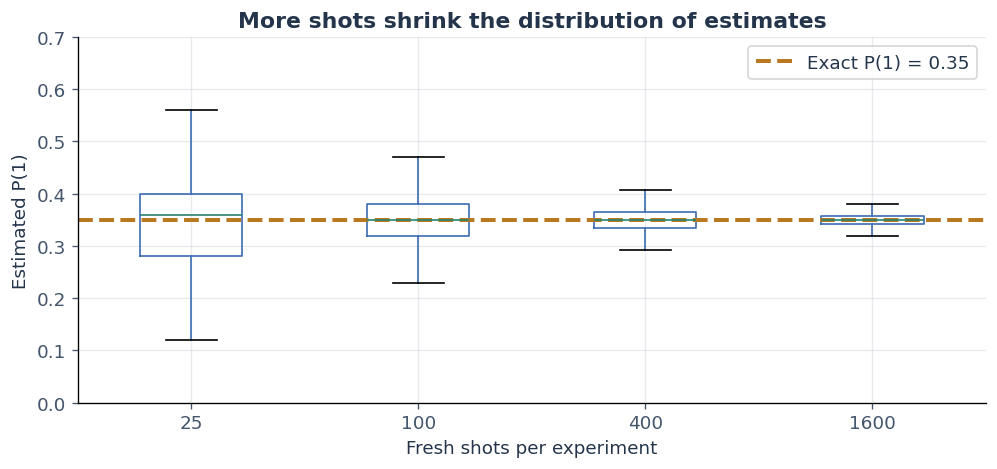

Boxes show the middle half of estimates; whiskers use 1.5 times the interquartile range, not confidence bounds.


In [7]:
budgets = np.array([25, 100, 400, 1600])
repeated_runs = 4000
estimates_by_budget = [rng.binomial(int(n), p, size=repeated_runs) / n for n in budgets]
predicted_spreads = np.sqrt(p * (1 - p) / budgets)
measured_spreads = np.array([values.std(ddof=1) for values in estimates_by_budget])
for n, predicted, measured in zip(budgets, predicted_spreads, measured_spreads):
    print(f"{n:4d} shots: predicted spread {predicted:.6f}; simulated spread {measured:.6f}")
assert np.allclose(measured_spreads, predicted_spreads, rtol=0.08, atol=0)
assert np.allclose(predicted_spreads[:-1] / predicted_spreads[1:], 2)
fig, ax = plt.subplots(layout="constrained")
ax.boxplot(estimates_by_budget, tick_labels=[str(n) for n in budgets], showfliers=False,
           medianprops={"color": GREEN}, boxprops={"color": BLUE}, whiskerprops={"color": BLUE})
ax.axhline(p, color=AMBER, linestyle="--", label="Exact P(1) = 0.35")
ax.set(xlabel="Fresh shots per experiment", ylabel="Estimated P(1)", ylim=(0, 0.7),
       title="More shots shrink the distribution of estimates")
ax.legend()
plt.show()
print("Boxes show the middle half of estimates; whiskers use 1.5 times the interquartile range, not confidence bounds.")

## 8. Check what a Z measurement does to a later X measurement

Prepare `|+⟩`. An immediate X measurement gives `+` with certainty. If you first measure Z, the known conditional state is `|0⟩` or `|1⟩`; each then gives `+` and `−` with equal probability in X.

If you **ignore** the Z result, you describe an ensemble: half the runs have state `|0⟩`, half have state `|1⟩`. Average their **probabilities**, not their amplitudes. This is a measurement-disturbed preparation, not an untouched `|+⟩` state.

In [8]:
plus = np.array([1, 1], dtype=complex) / np.sqrt(2)
zero = np.array([1, 0], dtype=complex)
one = np.array([0, 1], dtype=complex)
before = x_probabilities(plus)
after_ignored_z = 0.5 * x_probabilities(zero) + 0.5 * x_probabilities(one)
print("X measurement of untouched |+>:", np.round(before, 6))
print("X measurement after known Z=0:", np.round(x_probabilities(zero), 6))
print("X measurement after known Z=1:", np.round(x_probabilities(one), 6))
print("X measurement after ignoring the Z result:", np.round(after_ignored_z, 6))
assert np.allclose(before, [1, 0])
assert np.allclose(after_ignored_z, [0.5, 0.5])
print("Measurement basis and whether the state was re-prepared are part of the experimental question.")

X measurement of untouched |+>: [1. 0.]
X measurement after known Z=0: [0.5 0.5]
X measurement after known Z=1: [0.5 0.5]
X measurement after ignoring the Z result: [0.5 0.5]
Measurement basis and whether the state was re-prepared are part of the experimental question.


## 9. Predict a new state before computing it

Try `θ = 120°`, `φ = 60°`. Predict Z probabilities from `sin²(θ/2)` and X probabilities from `x = sin θ cos φ`. Predict whether adding a shared `40°` phase changes either answer. The output below is a worked check, not another sampling run.

In [9]:
test_state = qubit(np.deg2rad(120), np.deg2rad(60))
z_result = probabilities(test_state)
x_result = x_probabilities(test_state)
coordinates = bloch(test_state)
shared_rotation = np.exp(1j * np.deg2rad(40)) * test_state
print("Bloch [x, y, z]:", np.round(coordinates, 6))
print("Z [P(0), P(1)]:", np.round(z_result, 6))
print("X [P(+), P(-)]:", np.round(x_result, 6))
assert np.allclose(z_result, [0.25, 0.75])
assert np.allclose(x_result, [(1 + np.sqrt(3) / 4) / 2, (1 - np.sqrt(3) / 4) / 2])
assert np.allclose(probabilities(shared_rotation), z_result)
assert np.allclose(x_probabilities(shared_rotation), x_result)
print("All checks passed: normalized states, basis-dependent probabilities, and global-phase invariance.")

Bloch [x, y, z]: [ 0.433013  0.75     -0.5     ]
Z [P(0), P(1)]: [0.25 0.75]
X [P(+), P(-)]: [0.716506 0.283494]
All checks passed: normalized states, basis-dependent probabilities, and global-phase invariance.


**Try a change locally:** keep `θ = 120°` and replace `φ = 60°` with `180°`. Z probabilities should stay fixed; X probabilities should change. Then change the shot budget in section 6. Predict the distribution's spread before running section 7 again.

**Take this with you:** amplitudes determine probabilities in a chosen basis. A pure qubit's phase information can be invisible in Z and visible in X. A conditional measurement changes the state; fresh preparation resets it. Finite-shot estimates fluctuate even when the ideal model is exact.

Reference: [IBM, Basics of quantum information](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information).